In [55]:
import pandas as pd

In [56]:
df = pd.read_csv("titanic_dataset.csv")

df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [57]:
df.shape

(891, 12)

In [58]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [59]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [60]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [61]:
df.duplicated().sum()

np.int64(0)

In [62]:
df["Survived"].value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

In [63]:
df["Survived"].value_counts(normalize=True) * 100

Survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64

In [64]:
print(df["Sex"].value_counts())

Sex
male      577
female    314
Name: count, dtype: int64


In [65]:
print(df["Pclass"].value_counts().sort_index())

Pclass
1    216
2    184
3    491
Name: count, dtype: int64


In [66]:
print(df["Embarked"].value_counts(dropna=False))

Embarked
S      644
C      168
Q       77
NaN      2
Name: count, dtype: int64


In [67]:
df.groupby("Sex")["Survived"].mean() * 100

Sex
female    74.203822
male      18.890815
Name: Survived, dtype: float64

In [68]:
df.groupby("Pclass")["Survived"].mean() * 100

Pclass
1    62.962963
2    47.282609
3    24.236253
Name: Survived, dtype: float64

In [69]:
df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=[0, 12, 18, 35, 60, 100],
    labels=["Child", "Teenager", "Young Adult", "Adult", "Senior"]
)

df.groupby("AgeGroup", observed=True)["Survived"].mean() * 100

AgeGroup
Child          57.971014
Teenager       42.857143
Young Adult    38.268156
Adult          40.000000
Senior         22.727273
Name: Survived, dtype: float64

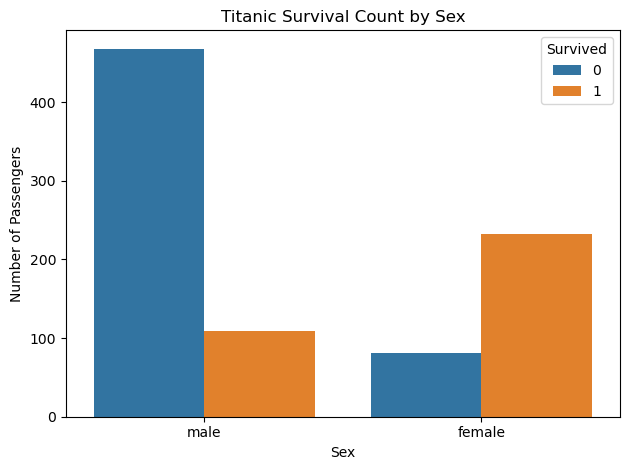

In [70]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x="Sex", hue="Survived")

plt.title("Titanic Survival Count by Sex")
plt.xlabel("Sex")
plt.ylabel("Number of Passengers")
plt.tight_layout()
plt.show()

In [71]:
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1

df[["SibSp", "Parch", "FamilySize"]].head()

,SibSp,Parch,FamilySize
0,1,0,2
1,1,0,2
2,0,0,1
3,1,0,2
4,0,0,1


In [72]:
df["IsAlone"] = (df["FamilySize"] == 1).astype(int)

df[["FamilySize", "IsAlone"]].head()

,FamilySize,IsAlone
0,2,0
1,2,0
2,1,1
3,2,0
4,1,1


In [73]:
df["Title"] = df["Name"].str.extract(r",\s*([^.]*)\.")

df[["Name", "Title"]].head(10)

,Name,Title
0,"Braund, Mr. Owen Harris",Mr
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",Mrs
2,"Heikkinen, Miss. Laina",Miss
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",Mrs
4,"Allen, Mr. William Henry",Mr
5,"Moran, Mr. James",Mr
6,"McCarthy, Mr. Timothy J",Mr
7,"Palsson, Master. Gosta Leonard",Master
8,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",Mrs
9,"Nasser, Mrs. Nicholas (Adele Achem)",Mrs


In [74]:
df["Title"].value_counts()

Title
Mr              517
Miss            182
Mrs             125
Master           40
Dr                7
Rev               6
Mlle              2
Major             2
Col               2
the Countess      1
Capt              1
Ms                1
Sir               1
Lady              1
Mme               1
Don               1
Jonkheer          1
Name: count, dtype: int64

In [75]:
df[["SibSp", "Parch", "FamilySize", "IsAlone"]].head(10)

,SibSp,Parch,FamilySize,IsAlone
0,1,0,2,0
1,1,0,2,0
2,0,0,1,1
3,1,0,2,0
4,0,0,1,1
5,0,0,1,1
6,0,0,1,1
7,3,1,5,0
8,0,2,3,0
9,1,0,2,0


In [76]:
df["IsAlone"].value_counts()

IsAlone
1    537
0    354
Name: count, dtype: int64

In [77]:
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
df["IsAlone"] = (df["FamilySize"] == 1).astype(int)

In [78]:
df.groupby("FamilySize")["Survived"].agg(["count", "mean"])

,count,mean
FamilySize,,
1,537,0.303538
2,161,0.552795
3,102,0.578431
4,29,0.724138
5,15,0.200000
6,22,0.136364
7,12,0.333333
8,6,0.000000
11,7,0.000000


In [79]:
df[["SibSp", "Parch", "FamilySize", "IsAlone"]].head(10).to_string(index=False)

' SibSp  Parch  FamilySize  IsAlone\n     1      0           2        0\n     1      0           2        0\n     0      0           1        1\n     1      0           2        0\n     0      0           1        1\n     0      0           1        1\n     0      0           1        1\n     3      1           5        0\n     0      2           3        0\n     1      0           2        0'

In [80]:
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1

df["IsAlone"] = (df["FamilySize"] == 1).astype(int)

In [81]:
display(
    df[["SibSp", "Parch", "FamilySize", "IsAlone"]].head(10)
)

,SibSp,Parch,FamilySize,IsAlone
0,1,0,2,0
1,1,0,2,0
2,0,0,1,1
3,1,0,2,0
4,0,0,1,1
5,0,0,1,1
6,0,0,1,1
7,3,1,5,0
8,0,2,3,0
9,1,0,2,0


In [82]:
print("Family size counts:")
print(df["FamilySize"].value_counts().sort_index())

print("\nIsAlone counts:")
print(df["IsAlone"].value_counts())

Family size counts:
FamilySize
1     537
2     161
3     102
4      29
5      15
6      22
7      12
8       6
11      7
Name: count, dtype: int64

IsAlone counts:
IsAlone
1    537
0    354
Name: count, dtype: int64


In [83]:
df.loc[:9, ["SibSp", "Parch", "FamilySize", "IsAlone"]].to_dict("records")

[{'SibSp': 1, 'Parch': 0, 'FamilySize': 2, 'IsAlone': 0},
 {'SibSp': 1, 'Parch': 0, 'FamilySize': 2, 'IsAlone': 0},
 {'SibSp': 0, 'Parch': 0, 'FamilySize': 1, 'IsAlone': 1},
 {'SibSp': 1, 'Parch': 0, 'FamilySize': 2, 'IsAlone': 0},
 {'SibSp': 0, 'Parch': 0, 'FamilySize': 1, 'IsAlone': 1},
 {'SibSp': 0, 'Parch': 0, 'FamilySize': 1, 'IsAlone': 1},
 {'SibSp': 0, 'Parch': 0, 'FamilySize': 1, 'IsAlone': 1},
 {'SibSp': 3, 'Parch': 1, 'FamilySize': 5, 'IsAlone': 0},
 {'SibSp': 0, 'Parch': 2, 'FamilySize': 3, 'IsAlone': 0},
 {'SibSp': 1, 'Parch': 0, 'FamilySize': 2, 'IsAlone': 0}]

In [84]:
missing = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing_Count": missing,
    "Missing_Percentage": (missing / len(df) * 100).round(2)
})

missing_summary[missing_summary["Missing_Count"] > 0]

,Missing_Count,Missing_Percentage
Age,177,19.87
Cabin,687,77.10
Embarked,2,0.22
AgeGroup,177,19.87


In [85]:
print(df["Survived"].value_counts(dropna=False))

Survived
0    549
1    342
Name: count, dtype: int64


In [86]:
# Remove the temporary EDA column
df = df.drop(columns=["AgeGroup"], errors="ignore")

# Define input features
feature_columns = [
    "Pclass",
    "Sex",
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "Embarked",
    "FamilySize",
    "IsAlone",
    "Title"
]

X = df[feature_columns].copy()
y = df["Survived"].copy()

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())

Feature shape: (891, 10)
Target shape: (891,)


,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,FamilySize,IsAlone,Title
0,3,male,22.0,1,0,7.2500,S,2,0,Mr
1,1,female,38.0,1,0,71.2833,C,2,0,Mrs
2,3,female,26.0,0,0,7.9250,S,1,1,Miss
3,1,female,35.0,1,0,53.1000,S,2,0,Mrs
4,3,male,35.0,0,0,8.0500,S,1,1,Mr


In [87]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (712, 10)
Testing features: (179, 10)
Training target: (712,)
Testing target: (179,)


In [88]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression

numeric_features = [
    "Age", "Fare", "SibSp", "Parch", "FamilySize", "IsAlone"
]

categorical_features = [
    "Pclass", "Sex", "Embarked", "Title"
]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [89]:
# Train the complete pipeline
model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [90]:
# Predict survival labels for unseen test data
y_pred = model.predict(X_test)

print("First 10 actual outcomes:")
print(y_test.head(10).to_list())

print("\nFirst 10 predicted outcomes:")
print(y_pred[:10])

First 10 actual outcomes:
[0, 0, 1, 0, 1, 1, 1, 0, 0, 0]

First 10 predicted outcomes:
[0 0 0 0 1 1 1 1 0 0]


In [91]:
# Predict probabilities for the test passengers
y_prob = model.predict_proba(X_test)

print("First 10 survival probabilities:")
print(y_prob[:10])

First 10 survival probabilities:
[[0.94760486 0.05239514]
 [0.94266564 0.05733436]
 [0.87625176 0.12374824]
 [0.96825488 0.03174512]
 [0.30790728 0.69209272]
 [0.3581526  0.6418474 ]
 [0.26734647 0.73265353]
 [0.37000437 0.62999563]
 [0.71396428 0.28603572]
 [0.84685993 0.15314007]]


In [92]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print(f"Test Accuracy: {accuracy:.4f}")
print(f"Test Accuracy: {accuracy * 100:.2f}%")

Test Accuracy: 0.8380
Test Accuracy: 83.80%


Confusion Matrix:
[[98 12]
 [17 52]]


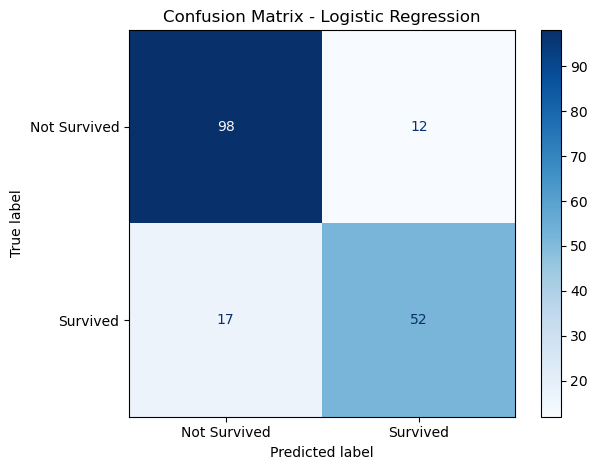

In [93]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Survived", "Survived"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix - Logistic Regression")
plt.tight_layout()
plt.show()

In [94]:
from sklearn.metrics import classification_report

print("Classification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Not Survived", "Survived"]
    )
)

Classification Report:
              precision    recall  f1-score   support

Not Survived       0.85      0.89      0.87       110
    Survived       0.81      0.75      0.78        69

    accuracy                           0.84       179
   macro avg       0.83      0.82      0.83       179
weighted avg       0.84      0.84      0.84       179



ROC-AUC Score: 0.8758


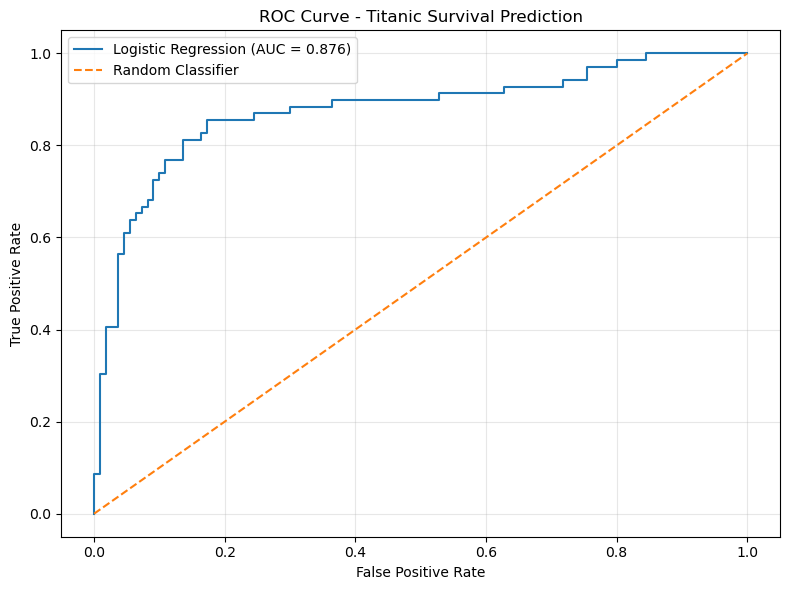

In [95]:
from sklearn.metrics import roc_curve, roc_auc_score

# Probability of the positive class: Survived = 1
y_prob_survived = model.predict_proba(X_test)[:, 1]

# Calculate ROC curve and AUC
fpr, tpr, thresholds = roc_curve(y_test, y_prob_survived)
auc_score = roc_auc_score(y_test, y_prob_survived)

print(f"ROC-AUC Score: {auc_score:.4f}")

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {auc_score:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Titanic Survival Prediction")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [96]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print(f"Final Test Accuracy: {accuracy * 100:.2f}%")

Final Test Accuracy: 83.80%


BASELINE MODEL
----------------------------------------
Accuracy: 0.8380
ROC-AUC:  0.8758

BEST HYPERPARAMETERS
----------------------------------------
{'classifier__C': 1, 'classifier__class_weight': None, 'classifier__solver': 'lbfgs'}

Best mean CV accuracy: 0.8231

TOP 10 CONFIGURATIONS


,C,Class Weight,Mean CV Accuracy,CV Std,Mean Train Accuracy
6,1.0,None,0.8231,0.0194,0.8315
14,100.0,None,0.8217,0.0199,0.8329
8,2.0,None,0.8216,0.0179,0.8325
2,0.1,None,0.8216,0.0241,0.8202
4,0.5,None,0.8216,0.0201,0.8276
10,5.0,None,0.8203,0.0184,0.8329
12,10.0,None,0.8203,0.0184,0.8325
3,0.1,balanced,0.8118,0.0193,0.8132
7,1.0,balanced,0.8104,0.0290,0.8164
5,0.5,balanced,0.8076,0.0253,0.8157



TUNED MODEL TEST RESULTS
----------------------------------------
Accuracy: 0.8380
Accuracy: 83.80%
ROC-AUC:  0.8758

Classification Report:
              precision    recall  f1-score   support

Not Survived       0.85      0.89      0.87       110
    Survived       0.81      0.75      0.78        69

    accuracy                           0.84       179
   macro avg       0.83      0.82      0.83       179
weighted avg       0.84      0.84      0.84       179

Confusion Matrix:
[[98 12]
 [17 52]]


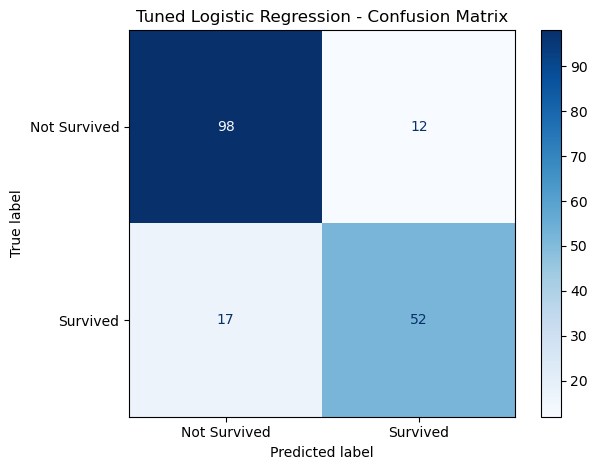

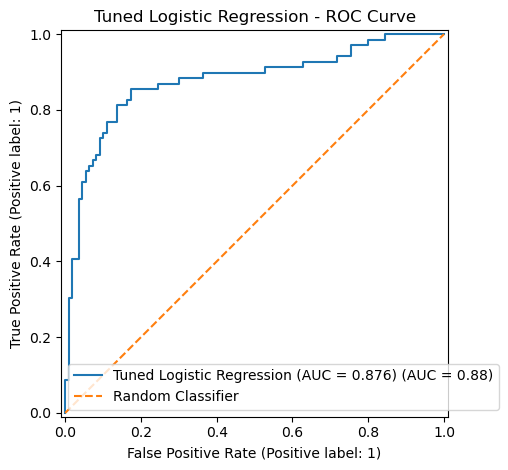


FINAL COMPARISON


,Model,Test Accuracy,Test ROC-AUC
0,Baseline Logistic Regression,0.838,0.8758
1,Tuned Logistic Regression,0.838,0.8758



Accuracy change: +0.00 percentage points
Both models achieved the same test accuracy.


In [97]:

# ============================================================
# TITANIC SURVIVAL PREDICTION
# Logistic Regression Hyperparameter Tuning with GridSearchCV
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    RocCurveDisplay
)

# ------------------------------------------------------------
# 1. BASELINE MODEL PERFORMANCE
# ------------------------------------------------------------

baseline_accuracy = accuracy_score(y_test, model.predict(X_test))
baseline_auc = roc_auc_score(
    y_test,
    model.predict_proba(X_test)[:, 1]
)

print("BASELINE MODEL")
print("-" * 40)
print(f"Accuracy: {baseline_accuracy:.4f}")
print(f"ROC-AUC:  {baseline_auc:.4f}")


# ------------------------------------------------------------
# 2. CREATE A MODEL FOR HYPERPARAMETER TUNING
# ------------------------------------------------------------

# Reuse your existing preprocessing pipeline.
# GridSearchCV will fit preprocessing separately within
# each cross-validation training fold.

tuning_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000))
])


# ------------------------------------------------------------
# 3. DEFINE HYPERPARAMETERS TO TEST
# ------------------------------------------------------------

param_grid = {
    "classifier__C": [0.01, 0.1, 0.5, 1, 2, 5, 10, 100],
    "classifier__class_weight": [None, "balanced"],
    "classifier__solver": ["lbfgs"]
}

# C controls regularization:
# Smaller C = stronger regularization.
# Larger C = weaker regularization.
#
# class_weight="balanced" gives more weight to the
# less frequent class during training.


# ------------------------------------------------------------
# 4. STRATIFIED CROSS-VALIDATION
# ------------------------------------------------------------

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


# ------------------------------------------------------------
# 5. SEARCH FOR THE BEST MODEL
# ------------------------------------------------------------

grid_search = GridSearchCV(
    estimator=tuning_pipeline,
    param_grid=param_grid,
    scoring="accuracy",
    cv=cv,
    n_jobs=-1,
    refit=True,
    return_train_score=True
)

# IMPORTANT: Tune only on training data.
grid_search.fit(X_train, y_train)

print("\nBEST HYPERPARAMETERS")
print("-" * 40)
print(grid_search.best_params_)

print(
    f"\nBest mean CV accuracy: "
    f"{grid_search.best_score_:.4f}"
)


# ------------------------------------------------------------
# 6. COMPARE CROSS-VALIDATION RESULTS
# ------------------------------------------------------------

cv_results = pd.DataFrame(grid_search.cv_results_)

results_table = cv_results[
    [
        "param_classifier__C",
        "param_classifier__class_weight",
        "mean_test_score",
        "std_test_score",
        "mean_train_score"
    ]
].sort_values("mean_test_score", ascending=False)

results_table = results_table.rename(columns={
    "param_classifier__C": "C",
    "param_classifier__class_weight": "Class Weight",
    "mean_test_score": "Mean CV Accuracy",
    "std_test_score": "CV Std",
    "mean_train_score": "Mean Train Accuracy"
})

print("\nTOP 10 CONFIGURATIONS")
display(results_table.head(10).round(4))


# ------------------------------------------------------------
# 7. EVALUATE THE TUNED MODEL ON THE TEST SET
# ------------------------------------------------------------

best_model = grid_search.best_estimator_

y_pred_tuned = best_model.predict(X_test)
y_prob_tuned = best_model.predict_proba(X_test)[:, 1]

tuned_accuracy = accuracy_score(y_test, y_pred_tuned)
tuned_auc = roc_auc_score(y_test, y_prob_tuned)

print("\nTUNED MODEL TEST RESULTS")
print("-" * 40)
print(f"Accuracy: {tuned_accuracy:.4f}")
print(f"Accuracy: {tuned_accuracy * 100:.2f}%")
print(f"ROC-AUC:  {tuned_auc:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_tuned,
    target_names=["Not Survived", "Survived"]
))


# ------------------------------------------------------------
# 8. PLOT THE TUNED MODEL CONFUSION MATRIX
# ------------------------------------------------------------

cm_tuned = confusion_matrix(y_test, y_pred_tuned)

print("Confusion Matrix:")
print(cm_tuned)

ConfusionMatrixDisplay(
    confusion_matrix=cm_tuned,
    display_labels=["Not Survived", "Survived"]
).plot(cmap="Blues", values_format="d")

plt.title("Tuned Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 9. PLOT THE ROC CURVE
# ------------------------------------------------------------

RocCurveDisplay.from_predictions(
    y_test,
    y_prob_tuned,
    name=f"Tuned Logistic Regression (AUC = {tuned_auc:.3f})"
)

plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title("Tuned Logistic Regression - ROC Curve")
plt.legend()
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 10. COMPARE BASELINE AND TUNED MODELS
# ------------------------------------------------------------

comparison = pd.DataFrame({
    "Model": ["Baseline Logistic Regression",
              "Tuned Logistic Regression"],
    "Test Accuracy": [baseline_accuracy, tuned_accuracy],
    "Test ROC-AUC": [baseline_auc, tuned_auc]
})

print("\nFINAL COMPARISON")
display(comparison.round(4))

accuracy_change = (tuned_accuracy - baseline_accuracy) * 100

print(
    f"\nAccuracy change: {accuracy_change:+.2f} percentage points"
)

if tuned_accuracy > baseline_accuracy:
    print("Tuned model achieved higher test accuracy.")
elif tuned_accuracy < baseline_accuracy:
    print("Tuned model achieved lower test accuracy.")
else:
    print("Both models achieved the same test accuracy.")


In [98]:
import pandas as pd
import matplotlib.pyplot as plt

# Retrieve the fitted preprocessing and Logistic Regression steps
fitted_preprocessor = model.named_steps["preprocessor"]
logistic_model = model.named_steps["classifier"]

# Get feature names after scaling and one-hot encoding
feature_names = fitted_preprocessor.get_feature_names_out()

# Extract Logistic Regression coefficients
coefficients = logistic_model.coef_[0]

# Create a DataFrame for interpretation
coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

# Sort by coefficient
coef_df = coef_df.sort_values(
    by="Coefficient",
    ascending=False
)

display(coef_df.round(4))

,Feature,Coefficient
20,categorical__Title_Master,1.5015
6,categorical__Pclass_1,0.9819
9,categorical__Sex_female,0.9140
24,categorical__Title_Mrs,0.4839
19,categorical__Title_Major,0.4241
27,categorical__Title_Sir,0.3494
12,categorical__Embarked_Q,0.3217
25,categorical__Title_Ms,0.1796
1,numeric__Fare,0.1627
18,categorical__Title_Lady,0.1042


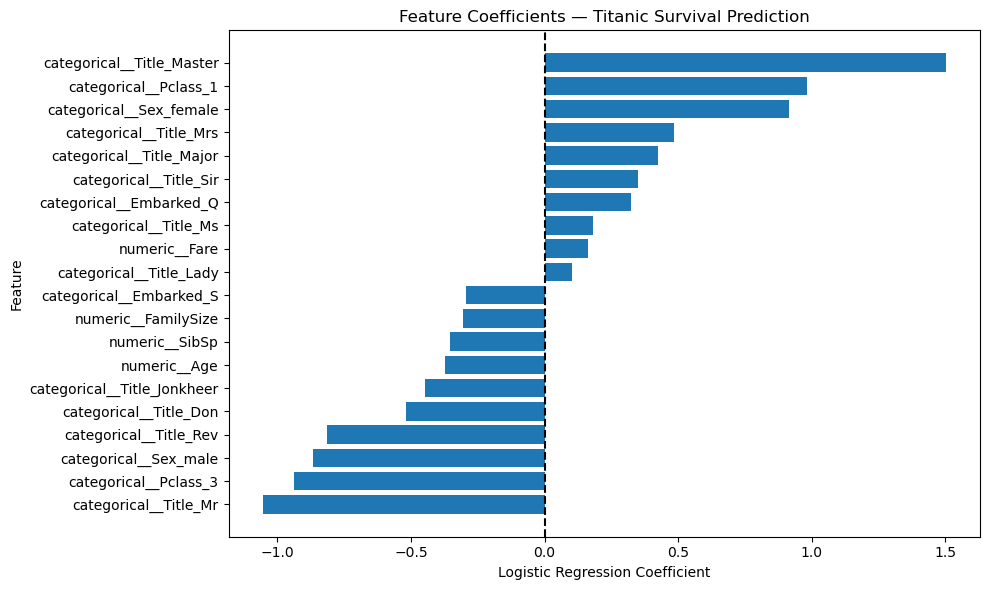

In [99]:
# Select the 10 most positive and 10 most negative coefficients
top_positive = coef_df.nlargest(10, "Coefficient")
top_negative = coef_df.nsmallest(10, "Coefficient")

plot_df = pd.concat(
    [top_negative, top_positive]
).drop_duplicates(subset="Feature")

plot_df = plot_df.sort_values("Coefficient")

plt.figure(figsize=(10, 6))

plt.barh(
    plot_df["Feature"],
    plot_df["Coefficient"]
)

plt.axvline(0, color="black", linestyle="--")
plt.xlabel("Logistic Regression Coefficient")
plt.ylabel("Feature")
plt.title("Feature Coefficients — Titanic Survival Prediction")
plt.tight_layout()
plt.show()

In [100]:
# Create sample passenger records using the model's input columns

sample_passengers = pd.DataFrame([
    {
        "Pclass": 1,
        "Sex": "female",
        "Age": 29,
        "SibSp": 0,
        "Parch": 0,
        "Fare": 80.0,
        "Embarked": "S",
        "FamilySize": 1,
        "IsAlone": 1,
        "Title": "Miss"
    },
    {
        "Pclass": 3,
        "Sex": "male",
        "Age": 30,
        "SibSp": 0,
        "Parch": 0,
        "Fare": 8.0,
        "Embarked": "S",
        "FamilySize": 1,
        "IsAlone": 1,
        "Title": "Mr"
    }
])

# Predict survival class and probability
sample_predictions = model.predict(sample_passengers)
sample_probabilities = model.predict_proba(sample_passengers)[:, 1]

# Display results
sample_results = sample_passengers[["Pclass", "Sex", "Age", "Fare"]].copy()

sample_results["Predicted_Survived"] = sample_predictions
sample_results["Survival_Probability"] = sample_probabilities.round(4)

sample_results["Prediction_Label"] = sample_results[
    "Predicted_Survived"
].map({
    0: "Not Survived",
    1: "Survived"
})

display(sample_results)

,Pclass,Sex,Age,Fare,Predicted_Survived,Survival_Probability,Prediction_Label
0,1,female,29,80.0,1,0.918,Survived
1,3,male,30,8.0,0,0.076,Not Survived


In [101]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Select numerical columns, including the target
correlation_columns = [
    "Survived",
    "Pclass",
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "FamilySize",
    "IsAlone"
]

# Calculate the correlation matrix
correlation_matrix = df[correlation_columns].corr()

# Display correlations with the target
survival_correlation = (
    correlation_matrix["Survived"]
    .drop("Survived")
    .sort_values(ascending=False)
)

print("Correlation with Survived:")
display(survival_correlation.to_frame())

Correlation with Survived:


,Survived
Fare,0.257307
Parch,0.081629
FamilySize,0.016639
SibSp,-0.035322
Age,-0.077221
IsAlone,-0.203367
Pclass,-0.338481


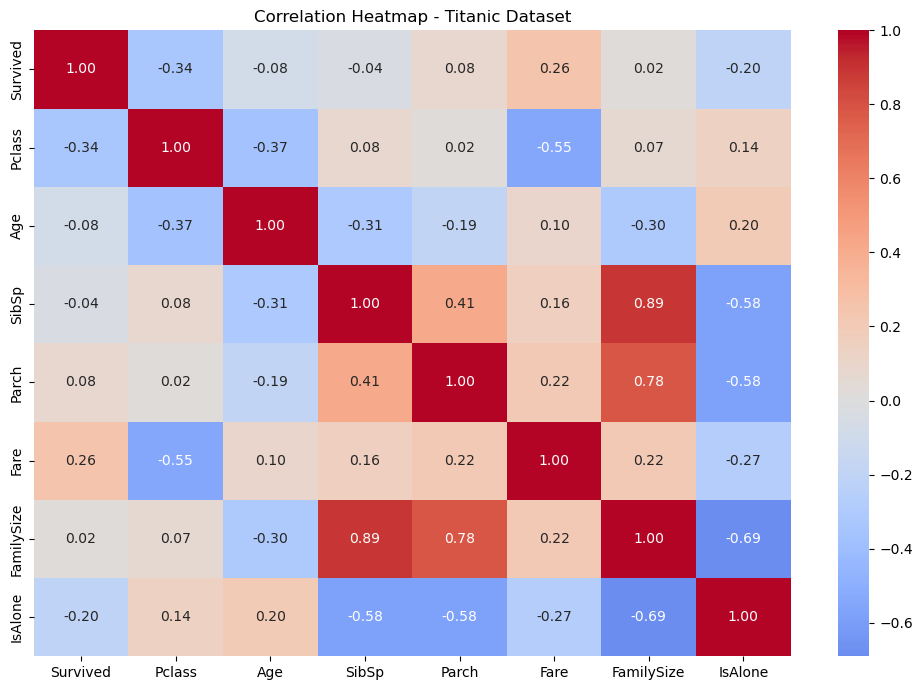

In [102]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Correlation Heatmap - Titanic Dataset")
plt.tight_layout()
plt.show()

In [103]:
import numpy as np

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

# Select two numerical features
X_2d = df[["Age", "Fare"]].copy()
y_2d = df["Survived"].copy()

# Use a stratified split for this demonstration
X_2d_train, X_2d_test, y_2d_train, y_2d_test = train_test_split(
    X_2d,
    y_2d,
    test_size=0.20,
    random_state=42,
    stratify=y_2d
)

# Build a separate two-feature model
boundary_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000))
])

boundary_model.fit(X_2d_train, y_2d_train)

print("Two-feature visualization model trained.")

Two-feature visualization model trained.


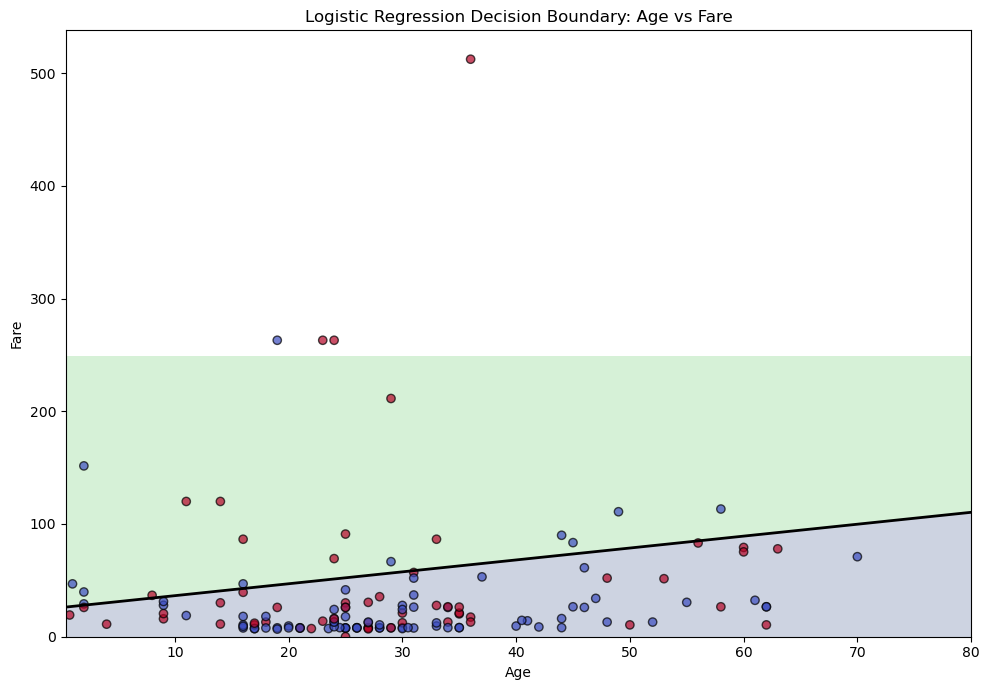

In [104]:
# Create a grid across the Age and Fare ranges
age_min = X_2d["Age"].min()
age_max = X_2d["Age"].max()

fare_min = X_2d["Fare"].min()
fare_max = X_2d["Fare"].quantile(0.99)

age_grid, fare_grid = np.meshgrid(
    np.linspace(age_min, age_max, 200),
    np.linspace(fare_min, fare_max, 200)
)

grid = pd.DataFrame({
    "Age": age_grid.ravel(),
    "Fare": fare_grid.ravel()
})

# Predict survival probabilities over the grid
probability_grid = boundary_model.predict_proba(grid)[:, 1]
probability_grid = probability_grid.reshape(age_grid.shape)

# Plot the decision regions and boundary
plt.figure(figsize=(10, 7))

plt.contourf(
    age_grid,
    fare_grid,
    probability_grid,
    levels=[0, 0.5, 1],
    alpha=0.25
)

plt.contour(
    age_grid,
    fare_grid,
    probability_grid,
    levels=[0.5],
    colors="black",
    linewidths=2
)

# Overlay the test passengers
plt.scatter(
    X_2d_test["Age"],
    X_2d_test["Fare"],
    c=y_2d_test,
    cmap="coolwarm",
    edgecolors="black",
    alpha=0.7
)

plt.xlabel("Age")
plt.ylabel("Fare")
plt.title("Logistic Regression Decision Boundary: Age vs Fare")
plt.tight_layout()
plt.show()

## Conclusion

In this project, I developed a Titanic Survival Prediction model using Logistic Regression, a supervised Machine Learning algorithm for binary classification. The dataset contained 891 passenger records and 12 original columns.

The workflow included data inspection, missing-value analysis, feature engineering, categorical encoding, numerical feature scaling, and an 80:20 train-test split. I created additional features such as `FamilySize`, `IsAlone`, and `Title` to capture useful passenger information.

The trained model achieved **83.80% test accuracy** and a **ROC-AUC score of 0.8758**. The confusion matrix showed 98 true negatives, 52 true positives, 12 false positives, and 17 false negatives. The classification report showed a precision of 0.81 and recall of 0.75 for the survived class.

I also visualized the confusion matrix and ROC curve, examined model coefficients to understand feature associations, and tested survival predictions for hypothetical passengers. Hyperparameter tuning using GridSearchCV did not improve test accuracy, which remained at 83.80%.

Overall, this project provided practical experience in data preprocessing, feature engineering, Logistic Regression, classification evaluation, and interpreting model predictions. Future improvements could include additional feature engineering, cross-validated model comparison, and further investigation of classification thresholds.